In [1]:
"""
WESAD Binary Stress Detection - Notebook 1: Data Acquisition & Loading
========================================================================
STRICT COMPLIANCE: LOSO-based subject-independent evaluation
Chest + Wrist + HRV with decision-level majority voting
"""

CONFIG = {
    # Task Configuration 
    'task_type': 'binary_classification', 
    'stress_label': 1,  
    'non_stress_label': 0,
    
    # Class Mapping (FIXED)
    'label_mapping': {
        'baseline': 0,      # Non-Stress
        'amusement': 0,     # Non-Stress
        'stress': 1,        # Stress
        'meditation': None  # Not used
    },
    
    # Modalities (FIXED - SEPARATE CHEST AND WRIST)
    'chest_signals': ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature'], 
    'wrist_signals': ['ACC', 'BVP', 'EDA', 'Temperature'],  # - Note: ACC is 3D
    'use_hrv': True,  # HRV features mandatory
    
    # Dataset
    'dataset_name': 'WESAD',  
    'num_subjects': 15,  
    'subject_ids': list(range(2, 18)),  # Subjects S2 to S17
    
    # Evaluation Protocol (FIXED)
    'evaluation': 'LOSO',  # FIXED: Leave-One-Subject-Out (MANDATORY)
}

In [2]:
# IMPORTS

import os
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
# DATASET PATH CONFIGURATION

# TODO: Set your WESAD dataset path
WESAD_PATH = "C:\\Users\\yomna.000\\Downloads\\grad project\\WESAD"   # TODO: Update this path

def verify_dataset_structure(base_path):
    """
    Verify WESAD dataset structure and return subject paths.
    
    Expected structure:
    WESAD/
    ├── S2/
    │   └── S2.pkl
    ├── S3/
    │   └── S3.pkl
    ...
    └── S17/
        └── S17.pkl
    """
    base_path = Path(base_path)
    
    if not base_path.exists():
        raise FileNotFoundError(f"Dataset path does not exist: {base_path}")
    
    subject_paths = {}
    missing_subjects = []
    
    for subject_id in CONFIG['subject_ids']:
        subject_name = f"S{subject_id}"
        subject_dir = base_path / subject_name
        subject_file = subject_dir / f"{subject_name}.pkl"
        
        if subject_file.exists():
            subject_paths[subject_name] = subject_file
        else:
            missing_subjects.append(subject_name)
    
    if missing_subjects:
        print(f"Warning: Missing subjects: {missing_subjects}")
    
    print(f"Found {len(subject_paths)} subjects")
    return subject_paths

In [4]:
# DATA LOADING FUNCTIONS

def load_subject_data(subject_path):
    """
    Load data for a single subject from WESAD .pkl file.
    
    Returns:
        dict: Subject data containing 'signal', 'label', and 'subject' info
    """
    with open(subject_path, 'rb') as f:
        data = pickle.load(f, encoding='latin1')
    return data

def extract_chest_signals(subject_data):
    """
    Extract chest-based signals (FIXED modalities).
    
    WESAD chest signal structure (RespiBAN, 700 Hz):
    The chest data is a structured array with named fields
    
    Returns:
        dict: Dictionary with signal names as keys and numpy arrays as values
    """
    chest_data = subject_data['signal']['chest']
    
    # WESAD uses structured arrays with field names
    signals = {
        'ECG': np.array(chest_data['ECG']).flatten(),          # FIXED
        'EDA': np.array(chest_data['EDA']).flatten(),          # FIXED
        'EMG': np.array(chest_data['EMG']).flatten(),          # FIXED
        'Temperature': np.array(chest_data['Temp']).flatten(),  # FIXED: Field name is 'Temp'
        'Respiration': np.array(chest_data['Resp']).flatten(),  # FIXED: Field name is 'Resp'
    }
    
    return signals

def extract_wrist_signals(subject_data):
    """
    Extract wrist-based signals (FIXED modalities).
    
    WESAD wrist signal structure (Empatica E4):
    The wrist data is a structured array with named fields
    
    Returns:
        dict: Dictionary with signal names as keys and numpy arrays as values
    """
    wrist_data = subject_data['signal']['wrist']
    
    # WESAD uses structured arrays with field names
    signals = {
        'ACC': np.array(wrist_data['ACC']),  # FIXED: 3D accelerometer (already correct shape)
        'BVP': np.array(wrist_data['BVP']).flatten(),    # FIXED
        'EDA': np.array(wrist_data['EDA']).flatten(),    # FIXED
        'Temperature': np.array(wrist_data['TEMP']).flatten(),  # FIXED: Field name is 'TEMP'
    }
    
    return signals

def extract_labels(subject_data):
    """
    Extract and map labels to binary classification.
    
    WESAD label encoding:
    - 0: Not defined
    - 1: Baseline → 0 (Non-Stress)
    - 2: Stress → 1 (Stress)
    - 3: Amusement → 0 (Non-Stress)
    - 4: Meditation → Not used
    
    Returns:
        numpy.ndarray: Binary labels (0 = Non-Stress, 1 = Stress)
    """
    labels = subject_data['label']
    
    # Create binary labels
    binary_labels = np.full_like(labels, -1, dtype=np.int32)
    
    # Map: Baseline (1) → 0
    binary_labels[labels == 1] = 0
    
    # Map: Stress (2) → 1
    binary_labels[labels == 2] = 1
    
    # Map: Amusement (3) → 0
    binary_labels[labels == 3] = 0
    
    # Meditation (4) and undefined (0) remain -1 (to be filtered)
    
    return binary_labels

def load_all_subjects(subject_paths):
    """
    Load data from all available subjects.
    Extracts BOTH chest AND wrist signals separately.
    
    Returns:
        dict: Dictionary with subject IDs as keys and processed data as values
    """
    all_data = {}
    
    for subject_id, subject_path in subject_paths.items():
        print(f"Loading {subject_id}...", end=' ')
        
        try:
            # Load raw data
            subject_data = load_subject_data(subject_path)
            
            # Extract chest signals
            chest_signals = extract_chest_signals(subject_data)
            
            # Extract wrist signals
            wrist_signals = extract_wrist_signals(subject_data)
            
            # Extract and map labels
            labels = extract_labels(subject_data)
            
            # Store processed data
            all_data[subject_id] = {
                'chest_signals': chest_signals,
                'wrist_signals': wrist_signals,
                'labels': labels,
                'chest_sampling_rate': 700,  # WESAD chest (RespiBAN)
                'wrist_sampling_rate': 64,   # WESAD wrist (Empatica E4 - highest rate)
            }
            
            print(f"✓ ({len(labels)} samples)")
            
        except Exception as e:
            print(f"✗ Error: {e}")
    
    return all_data

In [5]:
# DATA INSPECTION FUNCTIONS

def inspect_subject_data(subject_id, data):
    """Display basic statistics for a subject's data."""
    print(f"\n{'='*60}")
    print(f"Subject: {subject_id}")
    print(f"{'='*60}")
    
    chest_signals = data['chest_signals']
    wrist_signals = data['wrist_signals']
    labels = data['labels']
    
    # Chest signal shapes
    print("\nChest Signal Shapes (700 Hz):")
    for signal_name, signal_data in chest_signals.items():
        print(f"  {signal_name:15s}: {signal_data.shape}")
    
    # Wrist signal shapes
    print("\nWrist Signal Shapes (varying rates):")
    for signal_name, signal_data in wrist_signals.items():
        print(f"  {signal_name:15s}: {signal_data.shape}")
    
    # Label distribution
    print("\nLabel Distribution:")
    valid_labels = labels[labels != -1]
    unique, counts = np.unique(valid_labels, return_counts=True)
    for label, count in zip(unique, counts):
        label_name = "Stress" if label == 1 else "Non-Stress"
        print(f"  {label_name:15s} ({label}): {count:8d} samples ({count/len(valid_labels)*100:.1f}%)")
    
    print(f"  {'Undefined':15s} (-1): {np.sum(labels == -1):8d} samples")
    print(f"\nTotal samples: {len(labels)}")

def plot_signal_sample(subject_id, data, duration_seconds=60, start_second=0):
    """
    Plot a sample of signals for visual inspection.
    
    Args:
        subject_id: Subject identifier
        data: Subject data dictionary
        duration_seconds: Duration to plot (default 60 seconds)
        start_second: Starting point in seconds
    """
    chest_signals = data['chest_signals']
    wrist_signals = data['wrist_signals']
    labels = data['labels']
    
    chest_fs = data['chest_sampling_rate']
    
    start_idx = start_second * chest_fs
    end_idx = start_idx + (duration_seconds * chest_fs)
    
    # Ensure we don't exceed array bounds
    end_idx = min(end_idx, len(labels))
    
    fig, axes = plt.subplots(10, 1, figsize=(15, 14))
    fig.suptitle(f'Signal Sample - Subject {subject_id} ({duration_seconds}s)', fontsize=16, fontweight='bold')
    
    time_axis = np.arange(start_idx, end_idx) / chest_fs
    
    # Plot chest signals
    axes[0].plot(time_axis, chest_signals['ECG'][start_idx:end_idx], linewidth=0.5, color='blue')
    axes[0].set_ylabel('ECG', fontsize=11, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xlim([time_axis[0], time_axis[-1]])
    
    axes[1].plot(time_axis, chest_signals['EDA'][start_idx:end_idx], linewidth=0.5, color='green')
    axes[1].set_ylabel('EDA (Chest)', fontsize=11, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xlim([time_axis[0], time_axis[-1]])
    
    axes[2].plot(time_axis, chest_signals['EMG'][start_idx:end_idx], linewidth=0.5, color='red')
    axes[2].set_ylabel('EMG', fontsize=11, fontweight='bold')
    axes[2].grid(True, alpha=0.3)
    axes[2].set_xlim([time_axis[0], time_axis[-1]])
    
    axes[3].plot(time_axis, chest_signals['Respiration'][start_idx:end_idx], linewidth=0.5, color='purple')
    axes[3].set_ylabel('Respiration', fontsize=11, fontweight='bold')
    axes[3].grid(True, alpha=0.3)
    axes[3].set_xlim([time_axis[0], time_axis[-1]])
    
    axes[4].plot(time_axis, chest_signals['Temperature'][start_idx:end_idx], linewidth=0.8, color='orange')
    axes[4].set_ylabel('Temperature\n(Chest)', fontsize=11, fontweight='bold')
    axes[4].grid(True, alpha=0.3)
    axes[4].set_xlim([time_axis[0], time_axis[-1]])
    
    # Plot wrist signals (sample at their native rates)
    # BVP at 64 Hz
    wrist_start_bvp = start_second * 64
    wrist_end_bvp = wrist_start_bvp + (duration_seconds * 64)
    wrist_end_bvp = min(wrist_end_bvp, len(wrist_signals['BVP']))
    time_axis_bvp = np.arange(wrist_start_bvp, wrist_end_bvp) / 64
    
    axes[5].plot(time_axis_bvp, wrist_signals['BVP'][wrist_start_bvp:wrist_end_bvp], linewidth=0.5, color='darkblue')
    axes[5].set_ylabel('BVP (Wrist)', fontsize=11, fontweight='bold')
    axes[5].grid(True, alpha=0.3)
    axes[5].set_xlim([time_axis[0], time_axis[-1]])
    
    # EDA at 4 Hz
    wrist_start_eda = start_second * 4
    wrist_end_eda = wrist_start_eda + (duration_seconds * 4)
    wrist_end_eda = min(wrist_end_eda, len(wrist_signals['EDA']))
    time_axis_eda = np.arange(wrist_start_eda, wrist_end_eda) / 4
    
    axes[6].plot(time_axis_eda, wrist_signals['EDA'][wrist_start_eda:wrist_end_eda], linewidth=1.0, color='darkgreen', marker='o', markersize=3)
    axes[6].set_ylabel('EDA (Wrist)', fontsize=11, fontweight='bold')
    axes[6].grid(True, alpha=0.3)
    axes[6].set_xlim([time_axis[0], time_axis[-1]])
    
    # ACC at 32 Hz (plot X-axis only)
    wrist_start_acc = start_second * 32
    wrist_end_acc = wrist_start_acc + (duration_seconds * 32)
    wrist_end_acc = min(wrist_end_acc, len(wrist_signals['ACC']))
    time_axis_acc = np.arange(wrist_start_acc, wrist_end_acc) / 32
    
    if wrist_signals['ACC'].ndim == 2:
        axes[7].plot(time_axis_acc, wrist_signals['ACC'][wrist_start_acc:wrist_end_acc, 0], linewidth=0.5, color='brown', label='X')
        axes[7].plot(time_axis_acc, wrist_signals['ACC'][wrist_start_acc:wrist_end_acc, 1], linewidth=0.5, color='olive', alpha=0.6, label='Y')
        axes[7].plot(time_axis_acc, wrist_signals['ACC'][wrist_start_acc:wrist_end_acc, 2], linewidth=0.5, color='cyan', alpha=0.6, label='Z')
        axes[7].legend(loc='upper right', fontsize=8)
    axes[7].set_ylabel('ACC (Wrist)', fontsize=11, fontweight='bold')
    axes[7].grid(True, alpha=0.3)
    axes[7].set_xlim([time_axis[0], time_axis[-1]])
    
    # Temperature at 4 Hz
    wrist_start_temp = start_second * 4
    wrist_end_temp = wrist_start_temp + (duration_seconds * 4)
    wrist_end_temp = min(wrist_end_temp, len(wrist_signals['Temperature']))
    time_axis_temp = np.arange(wrist_start_temp, wrist_end_temp) / 4
    
    axes[8].plot(time_axis_temp, wrist_signals['Temperature'][wrist_start_temp:wrist_end_temp], linewidth=1.0, color='darkorange', marker='s', markersize=3)
    axes[8].set_ylabel('Temperature\n(Wrist)', fontsize=11, fontweight='bold')
    axes[8].grid(True, alpha=0.3)
    axes[8].set_xlim([time_axis[0], time_axis[-1]])
    
    # Plot labels
    axes[9].plot(time_axis, labels[start_idx:end_idx], linewidth=1.5, color='black')
    axes[9].set_ylabel('Label', fontsize=11, fontweight='bold')
    axes[9].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold')
    axes[9].set_yticks([-1, 0, 1])
    axes[9].set_yticklabels(['Undefined', 'Non-Stress', 'Stress'])
    axes[9].grid(True, alpha=0.3)
    axes[9].set_xlim([time_axis[0], time_axis[-1]])
    
    # Add colored background for labels
    for i in range(len(time_axis) - 1):
        if labels[start_idx + i] == 1:  # Stress
            axes[9].axvspan(time_axis[i], time_axis[i+1], alpha=0.2, color='red')
        elif labels[start_idx + i] == 0:  # Non-stress
            axes[9].axvspan(time_axis[i], time_axis[i+1], alpha=0.2, color='green')
    
    plt.tight_layout()
    
    # Save plot
    output_path = Path('results')
    output_path.mkdir(exist_ok=True)
    plt.savefig(output_path / 'signal_sample_visualization.png', dpi=300, bbox_inches='tight')
    print(f"\n✓ Signal visualization saved to: results/signal_sample_visualization.png")
    
    plt.show()

WESAD BINARY STRESS DETECTION - NOTEBOOK 1: DATA ACQUISITION
EVALUATION PROTOCOL: LOSO (Leave-One-Subject-Out)

[1/4] Verifying dataset structure...
Found 15 subjects

[2/4] Loading subject data...
Loading BOTH chest and wrist signals separately...
Loading S2... ✓ (4255300 samples)
Loading S3... ✓ (4545100 samples)
Loading S4... ✓ (4496100 samples)
Loading S5... ✓ (4380600 samples)
Loading S6... ✓ (4949700 samples)
Loading S7... ✓ (3666600 samples)
Loading S8... ✓ (3826200 samples)
Loading S9... ✓ (3656100 samples)
Loading S10... ✓ (3847200 samples)
Loading S11... ✓ (3663100 samples)
Loading S13... ✓ (3875900 samples)
Loading S14... ✓ (3883600 samples)
Loading S15... ✓ (3676400 samples)
Loading S16... ✓ (3941700 samples)
Loading S17... ✓ (4144000 samples)

[3/5] Inspecting data...

Subject: S2

Chest Signal Shapes (700 Hz):
  ECG            : (4255300,)
  EDA            : (4255300,)
  EMG            : (4255300,)
  Temperature    : (4255300,)
  Respiration    : (4255300,)

Wrist Signal 

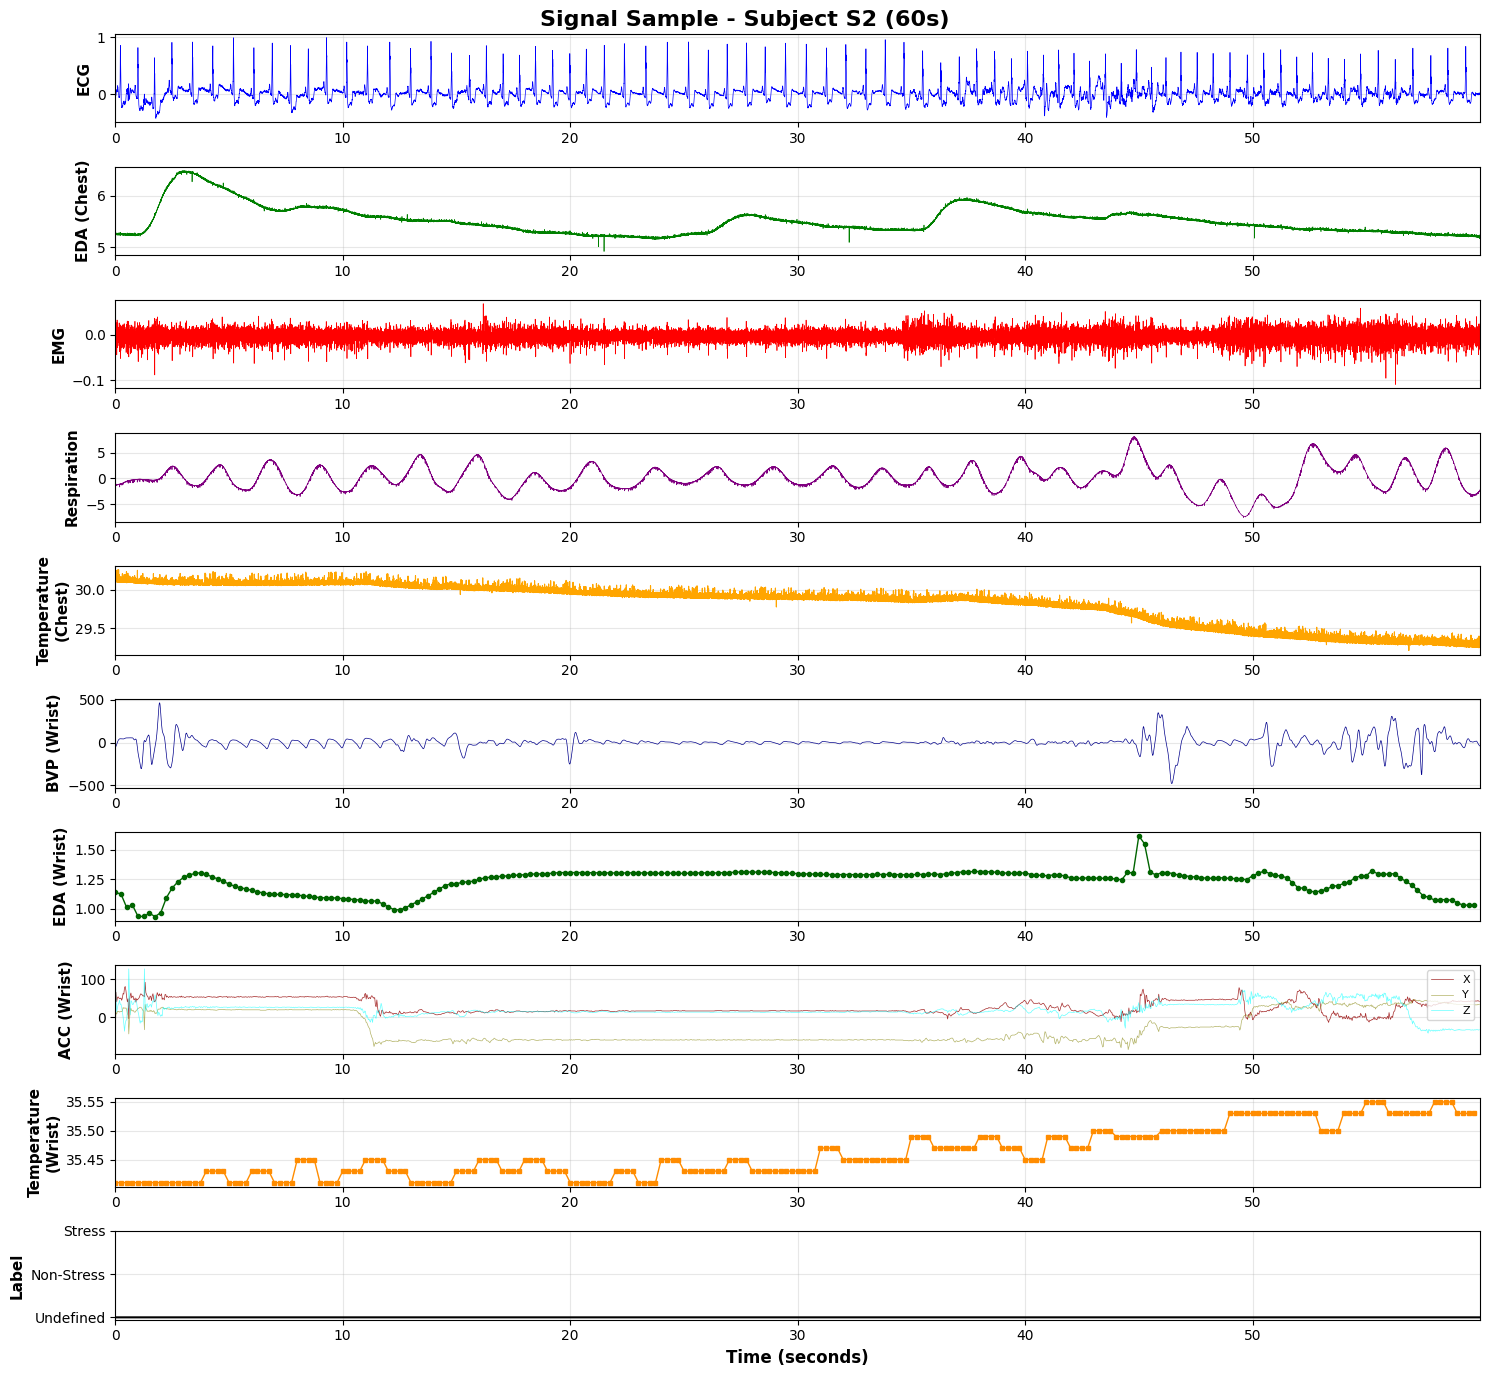


[5/5] Saving processed data...

Data saved to: processed_data\raw_loaded_data.pkl
Total subjects: 15

Each subject contains:
  - Chest signals: ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature']
  - Wrist signals: ['ACC', 'BVP', 'EDA', 'Temperature']
  - Labels (binary)

✓ Notebook 1 Complete - Proceed to Notebook 2 (Preprocessing + HRV)


In [6]:
# DATA SAVING FUNCTIONS

def save_processed_data(data, output_dir='processed_data'):
    """
    Save processed data for use in subsequent notebooks.
    
    Args:
        data: Dictionary of processed subject data
        output_dir: Output directory path
    """
    output_path = Path(output_dir)
    output_path.mkdir(exist_ok=True)
    
    output_file = output_path / 'raw_loaded_data.pkl'
    
    with open(output_file, 'wb') as f:
        pickle.dump({
            'data': data,
            'config': CONFIG
        }, f)
    
    print(f"\nData saved to: {output_file}")
    print(f"Total subjects: {len(data)}")
    print(f"\nEach subject contains:")
    print(f"  - Chest signals: {list(CONFIG['chest_signals'])}")
    print(f"  - Wrist signals: {list(CONFIG['wrist_signals'])}")
    print(f"  - Labels (binary)")

# MAIN EXECUTION

if __name__ == "__main__":
    print("="*70)
    print("WESAD BINARY STRESS DETECTION - NOTEBOOK 1: DATA ACQUISITION")
    print("EVALUATION PROTOCOL: LOSO (Leave-One-Subject-Out)")
    print("="*70)
    
    # Step 1: Verify dataset structure
    print("\n[1/4] Verifying dataset structure...")
    subject_paths = verify_dataset_structure(WESAD_PATH)
    
    # Step 2: Load all subjects
    print("\n[2/4] Loading subject data...")
    print("Loading BOTH chest and wrist signals separately...")
    all_data = load_all_subjects(subject_paths)
    
    # Step 3: Inspect first subject
    print("\n[3/5] Inspecting data...")
    if len(all_data) > 0:
        first_subject = list(all_data.keys())[0]
        inspect_subject_data(first_subject, all_data[first_subject])
    else:
        print("ERROR: No subjects loaded successfully!")
        print("Please check the WESAD dataset path and file format.")
        raise ValueError("Failed to load any subject data")
    
    # Step 4: Visualize signal sample
    print("\n[4/5] Visualizing signal sample (60 seconds)...")
    plot_signal_sample(first_subject, all_data[first_subject], duration_seconds=60)
    
    # Step 5: Save processed data
    print("\n[5/5] Saving processed data...")
    save_processed_data(all_data)
    
    print("\n" + "="*70)
    print("✓ Notebook 1 Complete - Proceed to Notebook 2 (Preprocessing + HRV)")
    print("="*70)